# 04b · Training ablations: bandwidth, C, class weighting, sampling

1. **Bandwidth sweep** (input scaling $c$), with C re-tuned at every $c$. Reports the error and the mean kernel value, so the
   concentration limits at both ends are visible.
2. **C sweep**, with $c$ fixed at the value the main run picked most often.
3. **Class weighting**: none vs `balanced`, for both QSVMs and the RBF SVM and logistic regression.
4. **Sampling of the training points**: random, near the boundary, or half and half, for both QSVMs, the RBF SVM and the MLP.

In [1]:
# Make the project helper package (qsvm_rc) importable from any sub-folder
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "qsvm_rc").is_dir() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: /kaggle/working/Project


In [2]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from qsvm_rc import config, data_utils, metrics, models, plots

SECTION = config.MAIN_SECTION
RESULTS_DIR = config.section_results_dir(SECTION, "ablations")
SWEEP_SIZE = 160

best_path = config.section_results_dir(SECTION, "qsvm") / "best_configs.json"
if best_path.exists():
    with open(best_path) as handle:
        best_configs = json.load(handle)
else:
    print("best_configs.json not found (run 03 first), using defaults")
    best_configs = {"angle": {"spec": {"kind": "angle"}, "bandwidth": 0.5, "C": 10},
                    "zz": {"spec": {"kind": "zz", "reps": 2, "entanglement": "linear"}, "bandwidth": 0.25, "C": 10}}
ANGLE_SPEC = best_configs["angle"]["spec"]
ZZ_SPEC = best_configs["zz"]["spec"]
best_configs

{'angle': {'spec': {'kind': 'angle'}, 'bandwidth': 0.5, 'C': 100.0},
 'zz': {'spec': {'kind': 'zz', 'reps': 2, 'entanglement': 'linear'},
  'bandwidth': 0.02,
  'C': 10000.0}}

In [3]:
frame = data_utils.load_section(SECTION)
splits = data_utils.load_splits(SECTION)
scaler = data_utils.domain_scaler(SECTION, frame)
test_rows, band_mask = data_utils.test_indices(splits)
x_test, y_test = data_utils.features_and_labels(frame, test_rows, scaler)
test_cache = models.ExactStateCache(x_test)

## 1. Bandwidth sweep

In [4]:
bandwidth_values = [0.01, 0.02, 0.05, 0.1, 0.25, 0.5, 0.75, 1, 1.5, 2]
bandwidth_models = {}
for bandwidth in bandwidth_values:
    bandwidth_models[f"angle|{bandwidth}"] = models.qsvm_fit_predict(ANGLE_SPEC, test_cache, fixed_bandwidth = bandwidth)
    bandwidth_models[f"zz|{bandwidth}"] = models.qsvm_fit_predict(ZZ_SPEC, test_cache, fixed_bandwidth = bandwidth)

bandwidth_results = models.run_learning_curve(bandwidth_models, frame, splits, scaler, sizes = [SWEEP_SIZE],
                                              save_path = RESULTS_DIR / "bandwidth_sweep.csv", verbose = False)
bandwidth_results["map"] = bandwidth_results["model"].str.split("|").str[0]
bandwidth_results["sweep_bandwidth"] = bandwidth_results["model"].str.split("|").str[1].astype(float)
bandwidth_results.to_csv(RESULTS_DIR / "bandwidth_sweep.csv", index = False)

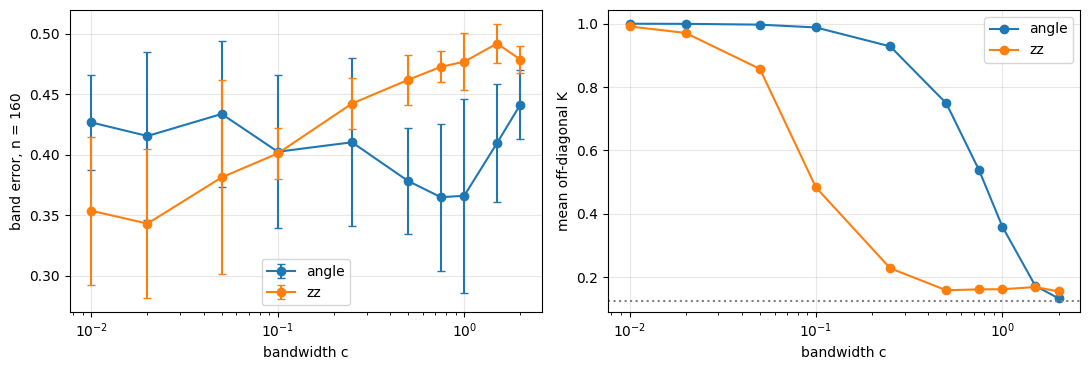

In [5]:
figure, axes = plt.subplots(1, 2, figsize = (11, 3.8))
for map_name in ["angle", "zz"]:
    part = bandwidth_results[bandwidth_results["map"] == map_name]
    error = metrics.summarise(part, "band_error", ("sweep_bandwidth",))
    kernel_mean = part.groupby("sweep_bandwidth")["mean_offdiag"].mean()
    axes[0].errorbar(error["sweep_bandwidth"], error["mean"], yerr = error["ci95"], marker = "o", capsize = 3, label = map_name)
    axes[1].plot(kernel_mean.index, kernel_mean.values, marker = "o", label = map_name)
for axis in axes:
    axis.set_xscale("log")
    axis.set_xlabel("bandwidth c")
    axis.grid(alpha = 0.3)
    axis.legend()
axes[0].set_ylabel(f"band error, n = {SWEEP_SIZE}")
axes[1].set_ylabel("mean off-diagonal K")
axes[1].axhline(1 / 8, color = "grey", linestyle = ":", label = "1 / 2^3")
figure.tight_layout()
figure.savefig(config.figures_dir() / "ablation_bandwidth_sweep.png", dpi = 200)
plt.show()

## 2. C sweep at the tuned bandwidth

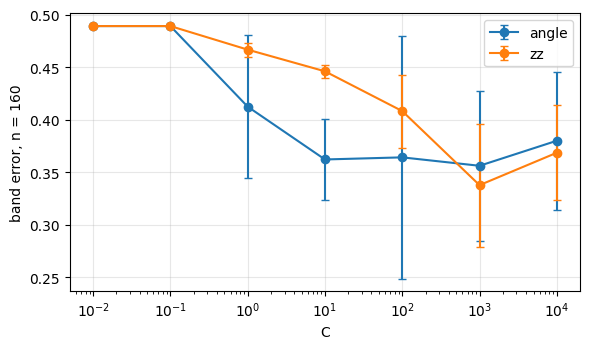

In [6]:
c_values = [0.01, 0.1, 1, 10, 100, 1000, 10000]
c_models = {}
for c_value in c_values:
    c_models[f"angle|{c_value}"] = models.qsvm_fit_predict(ANGLE_SPEC, test_cache, fixed_bandwidth = best_configs["angle"]["bandwidth"], fixed_c = c_value)
    c_models[f"zz|{c_value}"] = models.qsvm_fit_predict(ZZ_SPEC, test_cache, fixed_bandwidth = best_configs["zz"]["bandwidth"], fixed_c = c_value)
c_results = models.run_learning_curve(c_models, frame, splits, scaler, sizes = [SWEEP_SIZE], verbose = False)
c_results["map"] = c_results["model"].str.split("|").str[0]
c_results["sweep_C"] = c_results["model"].str.split("|").str[1].astype(float)
c_results.to_csv(RESULTS_DIR / "c_sweep.csv", index = False)

figure = plt.figure(figsize = (6, 3.6))
for map_name in ["angle", "zz"]:
    error = metrics.summarise(c_results[c_results["map"] == map_name], "band_error", ("sweep_C",))
    plt.errorbar(error["sweep_C"], error["mean"], yerr = error["ci95"], marker = "o", capsize = 3, label = map_name)
plt.xscale("log")
plt.xlabel("C")
plt.ylabel(f"band error, n = {SWEEP_SIZE}")
plt.grid(alpha = 0.3)
plt.legend()
plt.tight_layout()
figure.savefig(config.figures_dir() / "ablation_c_sweep.png", dpi = 200)
plt.show()

## 3. Class weighting

The data are about 31 percent SAFE. `balanced` weights each class by the inverse of its frequency.
Watch the false SAFE rate: weighting toward SAFE can raise it.

In [7]:
weighting_models = {}
for weight_name, weight in [("none", None), ("balanced", "balanced")]:
    weighting_models[f"qsvm_angle|{weight_name}"] = models.qsvm_fit_predict(ANGLE_SPEC, test_cache, class_weight = weight)
    weighting_models[f"qsvm_zz|{weight_name}"] = models.qsvm_fit_predict(ZZ_SPEC, test_cache, class_weight = weight)
    weighting_models[f"rbf_svm|{weight_name}"] = models.classical_fit_predict("rbf_svm", class_weight = weight)
    weighting_models[f"logistic|{weight_name}"] = models.classical_fit_predict("logistic", class_weight = weight)
weighting_results = models.run_learning_curve(weighting_models, frame, splits, scaler, sizes = [40, SWEEP_SIZE],
                                              save_path = RESULTS_DIR / "class_weighting.csv", verbose = False)
metrics.mean_ci_table(weighting_results, ["band_error", "test_balanced_accuracy", "test_false_safe_rate", "band_false_safe_rate"])

band_error test_balanced_accuracy  \
model               train_size                                           
logistic|balanced   40          0.487 +/- 0.030        0.932 +/- 0.007   
                    160         0.473 +/- 0.026        0.963 +/- 0.017   
logistic|none       40          0.432 +/- 0.042        0.951 +/- 0.023   
                    160         0.411 +/- 0.052        0.965 +/- 0.010   
qsvm_angle|balanced 40          0.472 +/- 0.020        0.931 +/- 0.037   
                    160         0.392 +/- 0.092        0.984 +/- 0.012   
qsvm_angle|none     40          0.436 +/- 0.037        0.943 +/- 0.021   
                    160         0.395 +/- 0.033        0.978 +/- 0.010   
qsvm_zz|balanced    40          0.468 +/- 0.005        0.877 +/- 0.046   
                    160         0.369 +/- 0.109        0.976 +/- 0.016   
qsvm_zz|none        40          0.453 +/- 0.003        0.916 +/- 0.064   
                    160         0.364 +/- 0.066        0.974 +/- 0.014   
rbf_svm|balanced    40          0.473 +/- 0.032        0.930 +/- 0.021   
                    160         0.394 +/- 0.083        0.984 +/- 0.009   
rbf_svm|none        40          0.443 +/- 0.023        0.943 +/- 0.015   
                    160         0.353 +/- 0.065        0.983 +/- 0.005   

                               test_false_safe_rate band_false_safe_rate  
model               train_size                                            
logistic|balanced   40              0.099 +/- 0.062      0.734 +/- 0.291  
                    160             0.054 +/- 0.044      0.759 +/- 0.131  
logistic|none       40              0.022 +/- 0.019      0.408 +/- 0.100  
                    160             0.024 +/- 0.012      0.479 +/- 0.183  
qsvm_angle|balanced 40              0.058 +/- 0.048      0.585 +/- 0.263  
                    160             0.022 +/- 0.018      0.627 +/- 0.190  
qsvm_angle|none     40              0.026 +/- 0.026      0.416 +/- 0.158  
                    160             0.018 +/- 0.016      0.513 +/- 0.302  
qsvm_zz|balanced    40              0.113 +/- 0.064      0.548 +/- 0.142  
                    160             0.022 +/- 0.016      0.478 +/- 0.118  
qsvm_zz|none        40              0.070 +/- 0.038      0.518 +/- 0.072  
                    160             0.023 +/- 0.015      0.449 +/- 0.165  
rbf_svm|balanced    40              0.075 +/- 0.056      0.623 +/- 0.365  
                    160             0.023 +/- 0.017      0.617 +/- 0.244  
rbf_svm|none        40              0.038 +/- 0.032      0.448 +/- 0.238  
                    160             0.016 +/- 0.015      0.451 +/- 0.241

## 4. Sampling of the training points

In [8]:
sampling_models = {
    "qsvm_angle": models.qsvm_fit_predict(ANGLE_SPEC, test_cache),
    "qsvm_zz": models.qsvm_fit_predict(ZZ_SPEC, test_cache),
    "rbf_svm": models.classical_fit_predict("rbf_svm"),
    "mlp": models.classical_fit_predict("mlp"),
}
sampling_frames = []
for strategy in config.SAMPLING_STRATEGIES:
    print("Strategy:", strategy)
    sampling_frames.append(models.run_learning_curve(sampling_models, frame, splits, scaler, sizes = [40, SWEEP_SIZE, 320],
                                                     strategy = strategy, verbose = False))
sampling_results = pd.concat(sampling_frames, ignore_index = True)
sampling_results.to_csv(RESULTS_DIR / "sampling_strategies.csv", index = False)
sampling_table = metrics.mean_ci_table(sampling_results, ["band_error", "test_balanced_accuracy", "test_false_safe_rate"],
                                       ("model", "strategy", "train_size"))
sampling_table.to_csv(RESULTS_DIR / "sampling_strategies_summary.csv")
sampling_table

Strategy: random
Strategy: boundary
Strategy: mixed


band_error test_balanced_accuracy  \
model      strategy train_size                                           
mlp        boundary 40          0.345 +/- 0.063        0.976 +/- 0.011   
                    160         0.182 +/- 0.049        0.993 +/- 0.003   
                    320         0.172 +/- 0.025        0.995 +/- 0.002   
           mixed    40          0.386 +/- 0.059        0.962 +/- 0.017   
                    160         0.261 +/- 0.032        0.986 +/- 0.006   
                    320         0.186 +/- 0.047        0.993 +/- 0.003   
           random   40          0.424 +/- 0.039        0.948 +/- 0.012   
                    160         0.347 +/- 0.082        0.977 +/- 0.015   
                    320         0.301 +/- 0.033        0.984 +/- 0.004   
qsvm_angle boundary 40          0.314 +/- 0.095        0.981 +/- 0.008   
                    160         0.158 +/- 0.058        0.994 +/- 0.003   
                    320         0.118 +/- 0.043        0.996 +/- 0.001   
           mixed    40          0.375 +/- 0.055        0.955 +/- 0.049   
                    160         0.232 +/- 0.058        0.989 +/- 0.007   
                    320         0.167 +/- 0.060        0.993 +/- 0.005   
           random   40          0.436 +/- 0.037        0.943 +/- 0.021   
                    160         0.395 +/- 0.033        0.978 +/- 0.010   
                    320         0.278 +/- 0.067        0.987 +/- 0.009   
qsvm_zz    boundary 40          0.382 +/- 0.064        0.967 +/- 0.018   
                    160         0.235 +/- 0.051        0.989 +/- 0.005   
                    320         0.178 +/- 0.062        0.992 +/- 0.004   
           mixed    40          0.403 +/- 0.043        0.948 +/- 0.050   
                    160         0.234 +/- 0.038        0.983 +/- 0.014   
                    320         0.193 +/- 0.041        0.990 +/- 0.008   
           random   40          0.453 +/- 0.003        0.916 +/- 0.064   
                    160         0.364 +/- 0.066        0.974 +/- 0.014   
                    320         0.316 +/- 0.065        0.982 +/- 0.008   
rbf_svm    boundary 40          0.357 +/- 0.059        0.974 +/- 0.012   
                    160         0.219 +/- 0.091        0.990 +/- 0.007   
                    320         0.125 +/- 0.030        0.996 +/- 0.003   
           mixed    40          0.421 +/- 0.036        0.946 +/- 0.039   
                    160         0.237 +/- 0.059        0.990 +/- 0.008   
                    320         0.144 +/- 0.053        0.995 +/- 0.002   
           random   40          0.443 +/- 0.023        0.943 +/- 0.015   
                    160         0.353 +/- 0.065        0.983 +/- 0.005   
                    320         0.359 +/- 0.075        0.979 +/- 0.008   

                               test_false_safe_rate  
model      strategy train_size                       
mlp        boundary 40              0.011 +/- 0.008  
                    160             0.002 +/- 0.001  
                    320             0.002 +/- 0.001  
           mixed    40              0.012 +/- 0.015  
                    160             0.007 +/- 0.010  
                    320             0.002 +/- 0.002  
           random   40              0.025 +/- 0.033  
                    160             0.014 +/- 0.011  
                    320             0.012 +/- 0.008  
qsvm_angle boundary 40              0.004 +/- 0.004  
                    160             0.001 +/- 0.001  
                    320             0.001 +/- 0.002  
           mixed    40              0.012 +/- 0.011  
                    160             0.002 +/- 0.001  
                    320             0.001 +/- 0.001  
           random   40              0.026 +/- 0.026  
                    160             0.018 +/- 0.016  
                    320             0.011 +/- 0.008  
qsvm_zz    boundary 40              0.007 +/- 0.005  
                    160             0.001 +/- 0.001  
                    320             

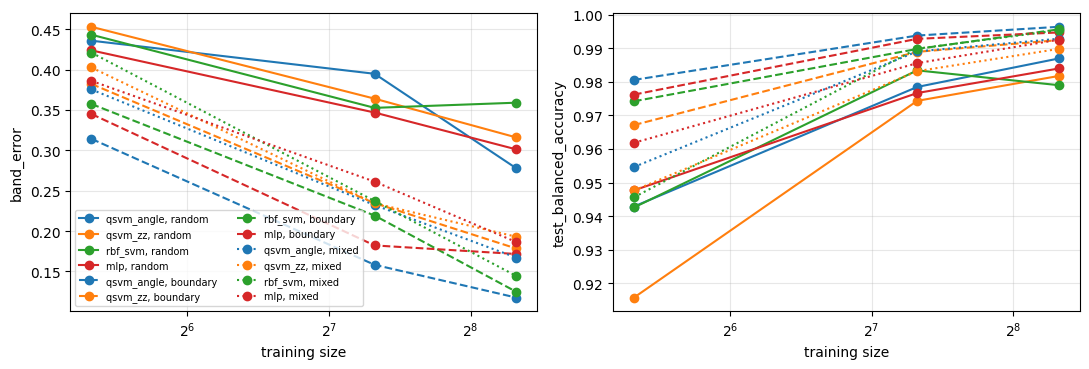

In [9]:
figure, axes = plt.subplots(1, 2, figsize = (11, 3.8))
for axis, metric_name in zip(axes, ["band_error", "test_balanced_accuracy"]):
    for strategy, style in zip(config.SAMPLING_STRATEGIES, ["-", "--", ":"]):
        for model_name, color in zip(sampling_models, ["tab:blue", "tab:orange", "tab:green", "tab:red"]):
            part = metrics.summarise(sampling_results[(sampling_results["strategy"] == strategy) & (sampling_results["model"] == model_name)], metric_name)
            axis.plot(part["train_size"], part["mean"], linestyle = style, color = color, marker = "o",
                      label = f"{model_name}, {strategy}" if metric_name == "band_error" else None)
    axis.set_xscale("log", base = 2)
    axis.set_xlabel("training size")
    axis.set_ylabel(metric_name)
    axis.grid(alpha = 0.3)
axes[0].legend(fontsize = 7, ncol = 2)
figure.tight_layout()
figure.savefig(config.figures_dir() / "ablation_sampling.png", dpi = 200)
plt.show()

In [10]:
# Does near-boundary sampling help the QSVM more than the RBF SVM? Paired, per strategy
for strategy in config.SAMPLING_STRATEGIES:
    part = sampling_results[sampling_results["strategy"] == strategy]
    for quantum_model in ["qsvm_angle", "qsvm_zz"]:
        pooled = metrics.paired_comparison(part, quantum_model, "rbf_svm", "band_error").iloc[-1]
        difference = pooled["mean_difference"]
        low = pooled["ci95_low"]
        high = pooled["ci95_high"]
        print(f"{strategy:<9} {quantum_model:<11} minus rbf_svm: {difference:+.4f} [{low:+.4f}, {high:+.4f}]")

random    qsvm_angle  minus rbf_svm: -0.0155 [-0.0636, +0.0327]
random    qsvm_zz     minus rbf_svm: -0.0073 [-0.0525, +0.0380]
boundary  qsvm_angle  minus rbf_svm: -0.0371 [-0.0675, -0.0068]
boundary  qsvm_zz     minus rbf_svm: +0.0313 [-0.0048, +0.0673]
mixed     qsvm_angle  minus rbf_svm: -0.0093 [-0.0390, +0.0205]
mixed     qsvm_zz     minus rbf_svm: +0.0091 [-0.0224, +0.0407]


Next: `04_ablations/03_other_sections.ipynb`.